# 🌍 Earth System Trend Detective — Regional Precipitation Analysis

### NASA Space Apps Challenge 2026 | India | October 2005–September 2025

**Purpose.** Compare monthly precipitation behaviour across East, South, Central, West and North India, quantify trend magnitude, and assess statistical evidence without confusing trend direction with statistical significance.

**Primary questions**
1. What is changing in each region?
2. Where are the estimated changes largest?
3. How large are the changes, in the source variable's units per year?
4. Is there statistical evidence of a monotonic trend?

> **Scientific transparency note:** the supplied CSV contains five regional monthly series, but it does not contain the geographic boundary definitions, area-weighting method, NASA product metadata, or extraction log. This notebook can validate the time series and analyse the supplied values; it cannot independently verify how the five regional averages were constructed. Complete the provenance fields in Section 2 before presenting these results as fully reproducible regional estimates.

**Study design:** 240 monthly records are expected from 2005-10-01 through 2025-09-01. The analysis uses monthly rate values as supplied. The unit is configurable below and must be checked against the original NASA Giovanni/export metadata.

## 1. Analysis workflow and methodological choices

- Validate dates, monthly continuity, missing values, duplicates and physically invalid negative values.
- Describe regional distributions and monthly climatology.
- Visualize monthly series, 12-month rolling means and month-specific anomalies.
- Calculate annual means only from complete calendar years; these remain **annual mean rates**, not annual accumulated rainfall.
- Estimate linear trend with OLS and Newey–West/HAC standard errors (12 monthly lags) to reduce sensitivity to serially correlated residuals.
- Estimate a **seasonal Kendall test** and **seasonal Sen slope** by comparing observations within the same calendar month across years.
- Diagnose residual/anomaly autocorrelation. Seasonal Mann–Kendall accounts for seasonality, but the standard seasonal test is not automatically corrected for serial autocorrelation; flagged results require cautious interpretation.
- Adjust the five regional Seasonal MK p-values using Benjamini–Hochberg false-discovery-rate control.
- Export clean tables and figures for the project report/dashboard.

**Important distinction:** the ordinary Theil–Sen slope and the seasonal Sen slope answer related but different questions. The seasonal Sen slope is the primary seasonally stratified magnitude estimate here. The ordinary Theil–Sen estimate is retained as a sensitivity comparison, not mislabeled as a seasonal estimate.

In [1]:
# 1.1 Imports and reproducibility settings
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import theilslopes, norm
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 180

RANDOM_SEED = 42
ALPHA = 0.05
HAC_MAXLAGS = 12
DATA_FILE = Path("All_region_India.csv")
OUTPUT_DIR = Path("regional_analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Verify this against the original NASA Giovanni/export metadata before final submission.
PRECIPITATION_UNIT = "mm/hr"  # editable metadata label; not inferable from CSV alone

## 2. Data provenance and study configuration

Fill these fields from the actual NASA Giovanni request/export and the method used to create `All_region_India.csv`. Do not guess region definitions or spatial averaging details. A blank field means the provenance is not yet documented.

In [2]:
# 2.1 Provenance record — COMPLETE FROM YOUR ACTUAL SOURCE/EXPORT
PROVENANCE = {
    "NASA_dataset_or_product": "GPM IMERG Final V07 (verify exact product/version in export)",
    "NASA_data_portal": "NASA Giovanni (confirm exact portal and workflow)",
    "variable_name_as_exported": "Precipitation (enter exact Giovanni variable label)",
    "source_units": PRECIPITATION_UNIT,
    "temporal_aggregation": "Monthly (confirm whether monthly mean rate or monthly accumulation)",
    "spatial_statistic": "Regional spatial mean (document area-weighted vs unweighted)",
    "region_boundary_definition": "NOT DOCUMENTED — enter exact states/polygon/boundary source for each region",
    "regional_extraction_method": "NOT DOCUMENTED — state whether each region was extracted separately or computed from gridded data",
    "spatial_resolution": "Enter source grid resolution from metadata",
    "source_download_date": "Enter date",
    "source_file_or_request_identifier": "Enter Giovanni request/export identifier if available",
}

missing_provenance = [k for k, v in PROVENANCE.items()
                      if not str(v).strip() or "NOT DOCUMENTED" in str(v).upper()
                      or str(v).startswith("Enter") or "(verify" in str(v) or "(confirm" in str(v)]
print("Provenance fields requiring confirmation:", missing_provenance)
if missing_provenance:
    print("STATUS: ANALYSIS-READY, BUT REGIONAL SPATIAL PROVENANCE IS NOT YET FULLY VERIFIED.")
else:
    print("STATUS: Provenance fields completed. Cross-check every entry against the source export.")

Provenance fields requiring confirmation: ['NASA_dataset_or_product', 'NASA_data_portal', 'temporal_aggregation', 'region_boundary_definition', 'regional_extraction_method', 'spatial_resolution', 'source_download_date', 'source_file_or_request_identifier']
STATUS: ANALYSIS-READY, BUT REGIONAL SPATIAL PROVENANCE IS NOT YET FULLY VERIFIED.


In [3]:
# 2.2 Load and standardize the supplied regional dataset
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Keep All_region_India.csv in the same folder as this notebook "
        "or update DATA_FILE to its correct path."
    )

raw = pd.read_csv(DATA_FILE)
raw.columns = raw.columns.astype(str).str.strip()
if "date" not in raw.columns:
    raise ValueError("The CSV must contain a 'date' column.")

raw["date"] = pd.to_datetime(raw["date"], dayfirst=True, errors="coerce")
region_cols = [c for c in raw.columns if c != "date"]
if len(region_cols) != 5:
    warnings.warn(f"Expected 5 regional columns; found {len(region_cols)}: {region_cols}")

for col in region_cols:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

df = (raw.dropna(subset=["date"])
          .sort_values("date")
          .reset_index(drop=True))

# Normalize every date to the first day of its calendar month.
df["date"] = df["date"].dt.to_period("M").dt.to_timestamp()
print("Dataset shape:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Regional series:", region_cols)
display(df.head())

Dataset shape: (240, 6)
Date range: 2005-10-01 to 2025-09-01
Regional series: ['mean_east_india', 'mean_south_india', 'mean_central_india', 'mean_west_india', 'mean_north_india']


,date,mean_east_india,mean_south_india,mean_central_india,mean_west_india,mean_north_india
0,2005-10-01,0.281501,0.381463,0.085060,0.025413,0.012919
1,2005-11-01,0.019111,0.307741,0.001217,0.000945,0.008817
2,2005-12-01,0.014711,0.179478,0.003284,0.000271,0.007862
3,2006-01-01,0.002767,0.027170,0.002203,0.000759,0.055723
4,2006-02-01,0.032251,0.007484,0.001822,0.000516,0.037017


## 3. Data-quality and temporal-integrity checks

The expected monthly index is generated from the first through last observed month. The analysis stops if duplicate months or missing monthly timestamps are found, because silently analysing an irregular series can invalidate rolling windows and seasonal tests.

In [4]:
expected_dates = pd.date_range(df["date"].min(), df["date"].max(), freq="MS")
observed_dates = pd.DatetimeIndex(df["date"].drop_duplicates()).sort_values()
missing_months = expected_dates.difference(observed_dates)
duplicate_months = int(df["date"].duplicated().sum())

quality_rows = []
for col in region_cols:
    quality_rows.append({
        "Region": col.replace("mean_", "").replace("_", " ").title(),
        "observations": int(df[col].notna().sum()),
        "missing_values": int(df[col].isna().sum()),
        "negative_values": int((df[col] < 0).sum()),
        "minimum": df[col].min(),
        "maximum": df[col].max(),
    })
quality = pd.DataFrame(quality_rows)
print("Rows:", len(df), "| Expected months:", len(expected_dates),
      "| Unique months:", len(observed_dates), "| Missing months:", len(missing_months),
      "| Duplicate month rows:", duplicate_months)
display(quality.round(6))

if duplicate_months:
    raise ValueError("Duplicate monthly timestamps detected. Resolve them before trend analysis.")
if len(missing_months):
    raise ValueError(f"Missing monthly timestamps detected: {list(missing_months[:10])}")
if quality["negative_values"].sum() > 0:
    raise ValueError("Negative precipitation values detected. Investigate source/quality flags before proceeding.")
if df[region_cols].isna().any().any():
    raise ValueError("Missing regional values detected. Do not silently interpolate; investigate source gaps first.")

quality.to_csv(OUTPUT_DIR / "data_quality_report.csv", index=False)
print("Quality checks passed for the supplied monthly table.")

Rows: 240 | Expected months: 240 | Unique months: 240 | Missing months: 0 | Duplicate month rows: 0


,Region,observations,missing_values,negative_values,minimum,maximum
0,East India,240,0,0,0.002249,0.669855
1,South India,240,0,0,0.001474,0.452639
2,Central India,240,0,0,0.000064,0.601875
3,West India,240,0,0,0.000036,0.564367
4,North India,240,0,0,0.003282,0.241080


Quality checks passed for the supplied monthly table.


## 4. Regional descriptive statistics

The values below describe the supplied variable in its configured source unit. Mean/median comparisons are descriptive; they do not imply a trend or statistical significance.

In [5]:
desc = df[region_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
desc = desc.rename(columns={"count":"n_months", "mean":"mean", "median":"median", "std":"std_dev", "min":"minimum", "max":"maximum"})
desc.index = [c.replace("mean_", "").replace("_", " ").title() for c in desc.index]
desc = desc.sort_values("mean", ascending=False)
display(desc.round(5))
desc.to_csv(OUTPUT_DIR / "regional_descriptive_statistics.csv")

,n_months,mean,median,std_dev,minimum,maximum
East India,240.0,0.20934,0.15071,0.19488,0.00225,0.66986
South India,240.0,0.16728,0.16840,0.12274,0.00147,0.45264
Central India,240.0,0.13204,0.03670,0.16896,0.00006,0.60188
West India,240.0,0.10352,0.01442,0.14604,0.00004,0.56437
North India,240.0,0.06637,0.05138,0.05311,0.00328,0.24108


## 5. Monthly precipitation time series and 12-month rolling means

The rolling mean smooths the within-year seasonal cycle; it is a visualization aid, not a replacement for the original monthly observations.

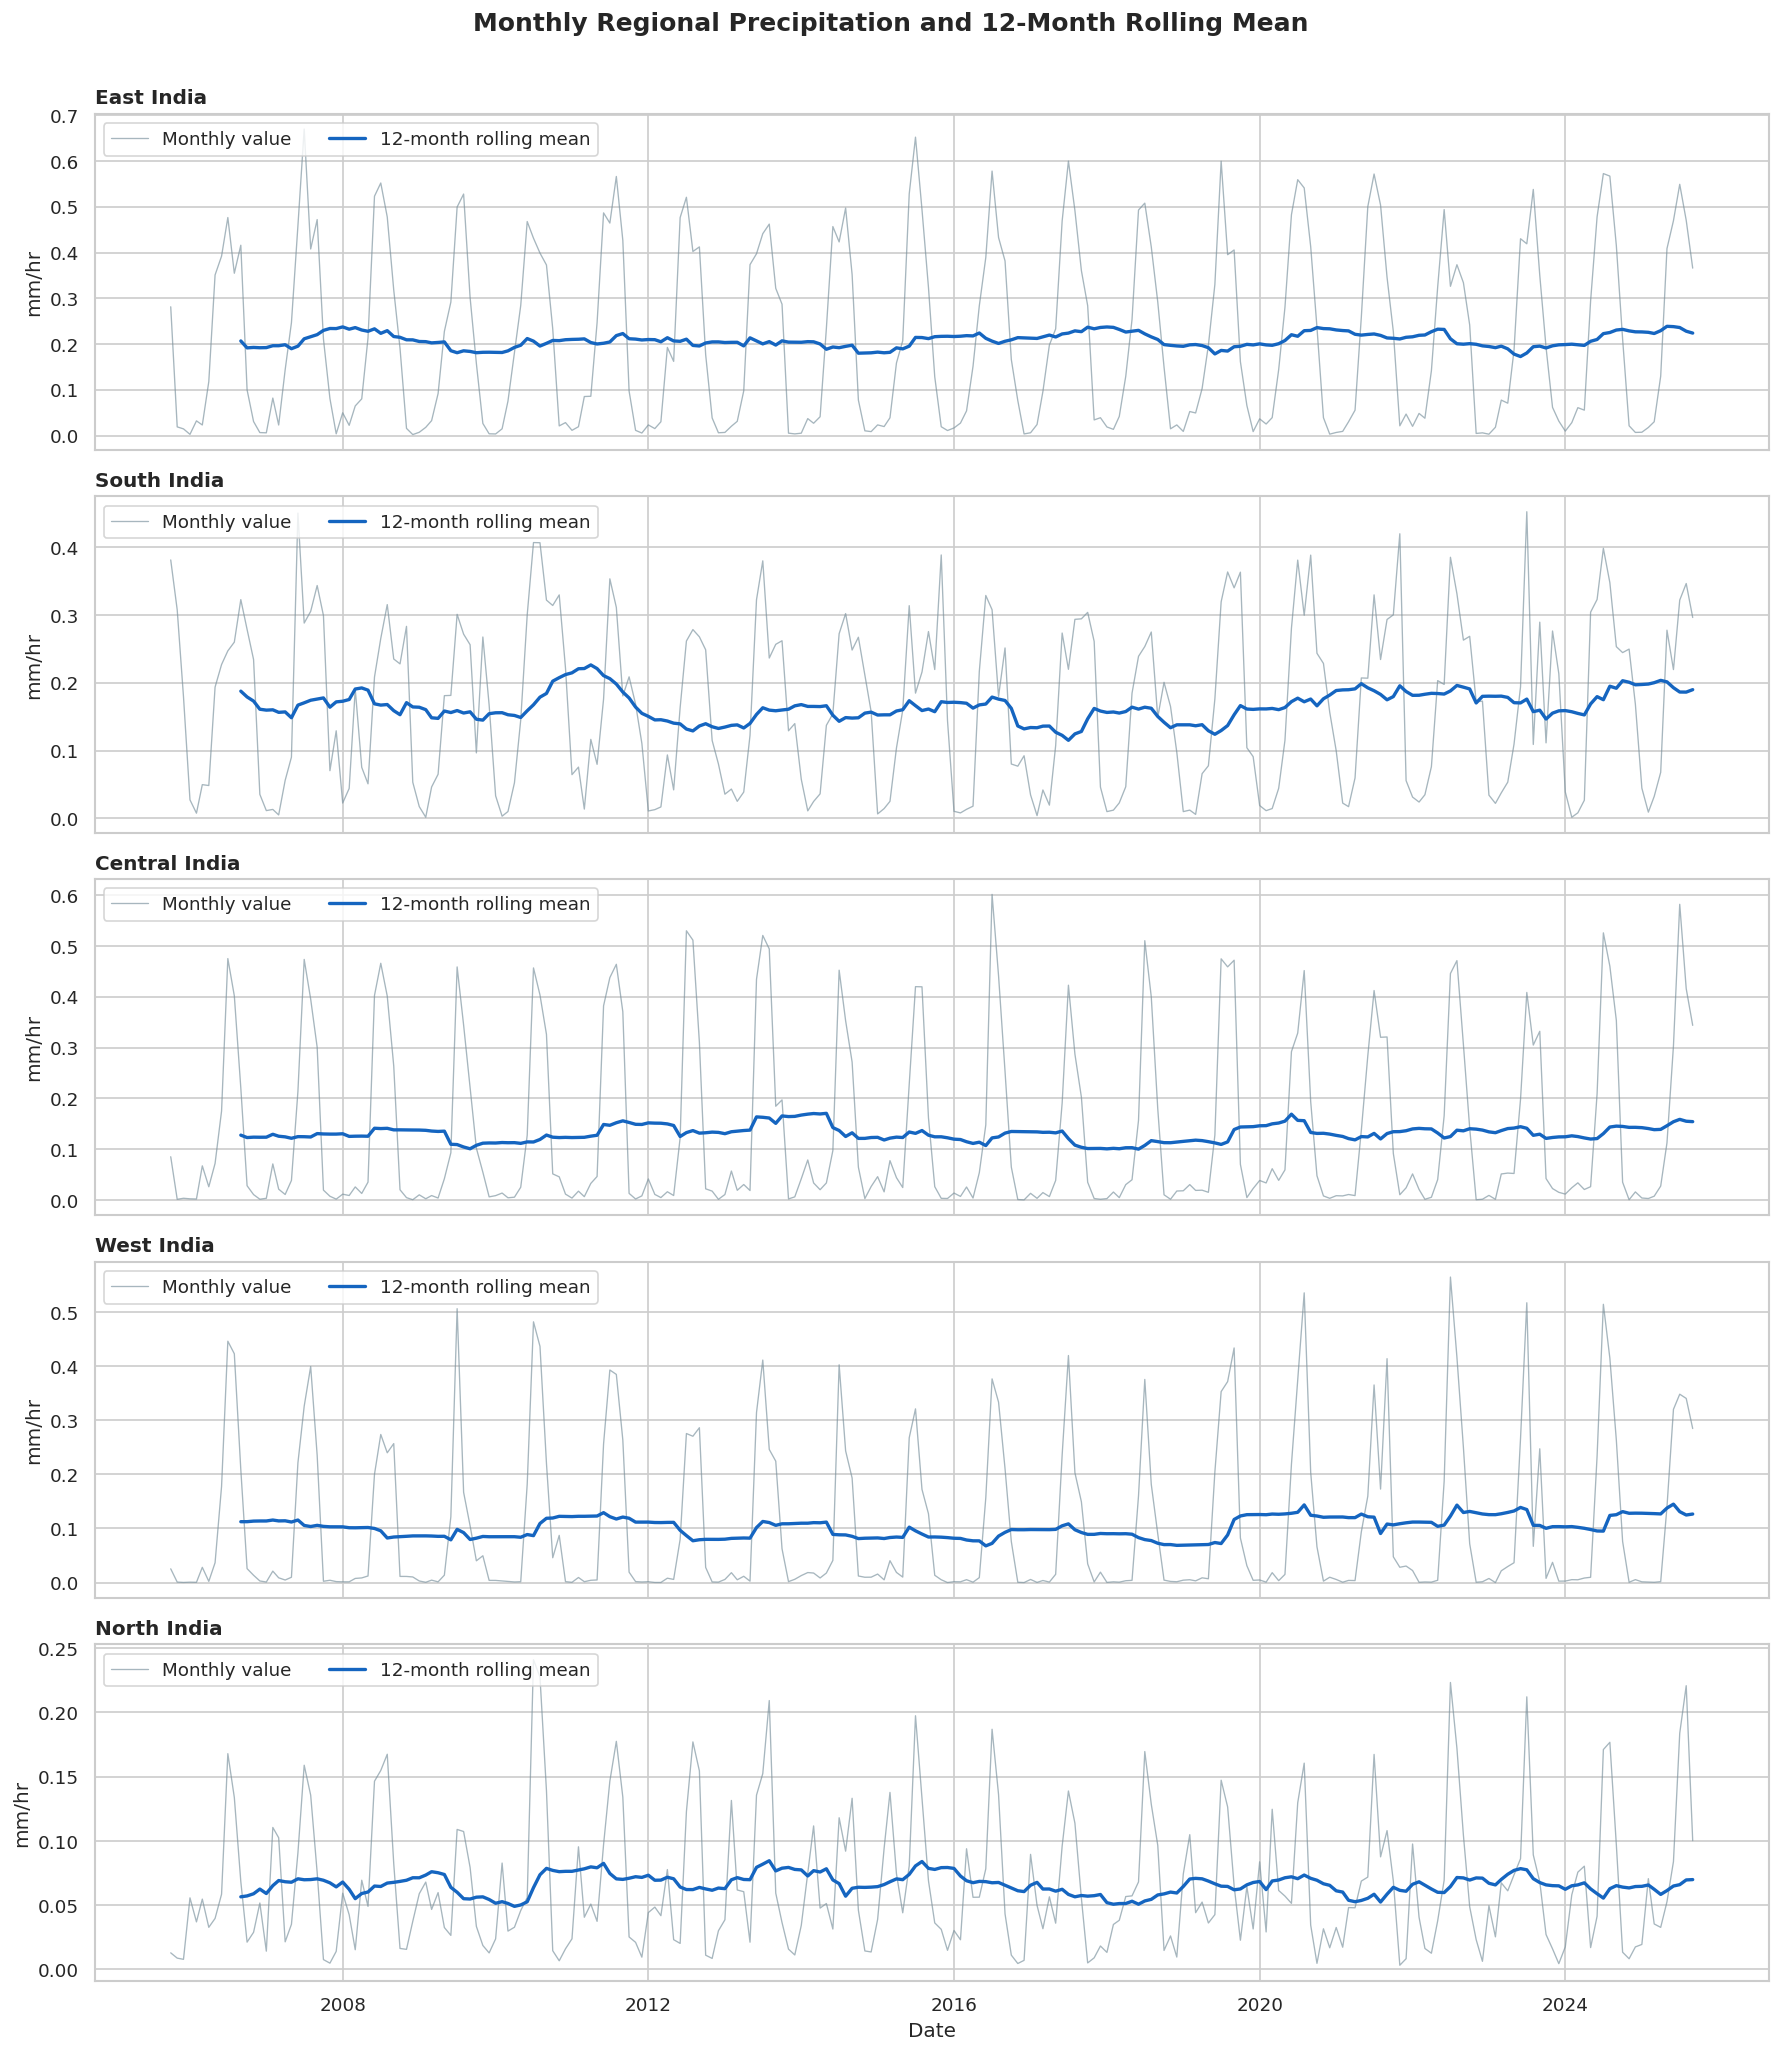

In [6]:
fig, axes = plt.subplots(len(region_cols), 1, figsize=(15, 17), sharex=True)
if len(region_cols) == 1: axes = [axes]
for ax, region in zip(axes, region_cols):
    ax.plot(df["date"], df[region], color="#78909c", lw=0.8, alpha=0.65, label="Monthly value")
    ax.plot(df["date"], df[region].rolling(12, min_periods=12).mean(), color="#1565c0", lw=2.0, label="12-month rolling mean")
    ax.set_title(region.replace("mean_", "").replace("_", " ").title(), loc="left", fontweight="bold")
    ax.set_ylabel(PRECIPITATION_UNIT)
    ax.legend(loc="upper left", ncol=2, frameon=True)
axes[-1].set_xlabel("Date")
fig.suptitle("Monthly Regional Precipitation and 12-Month Rolling Mean", y=1.005, fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_monthly_time_series.png", bbox_inches="tight")
plt.show()

## 6. Seasonal climatology

Monthly climatology is calculated by averaging all January values together, all February values together, and so on. It describes the typical seasonal cycle over the available study period.

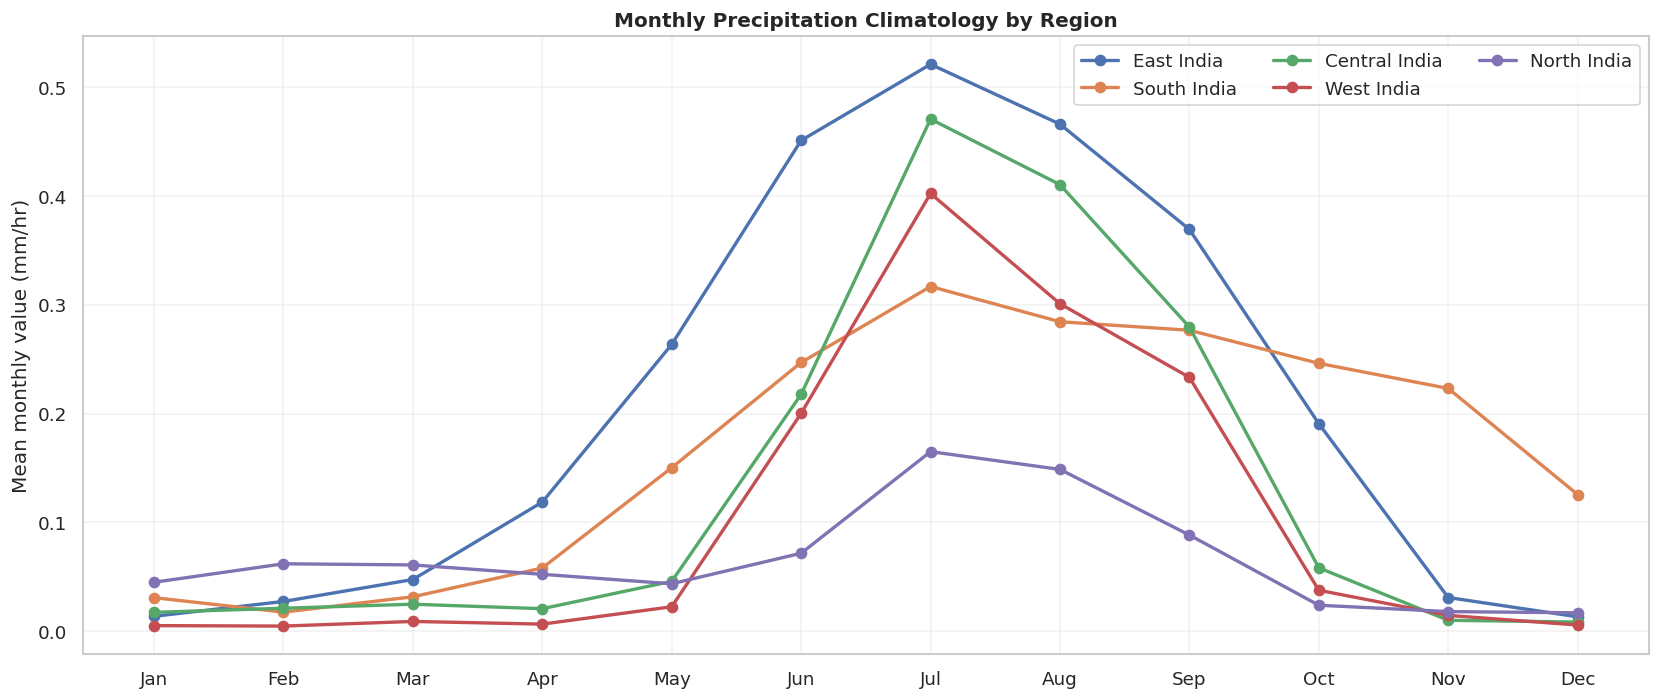

In [7]:
clim_data = df.set_index("date")[region_cols].copy()
climatology = clim_data.groupby(clim_data.index.month).mean()
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(14, 6))
for region in region_cols:
    ax.plot(range(1,13), climatology[region], marker="o", lw=2, label=region.replace("mean_", "").replace("_", " ").title())
ax.set_xticks(range(1,13), month_labels)
ax.set_ylabel(f"Mean monthly value ({PRECIPITATION_UNIT})")
ax.set_title("Monthly Precipitation Climatology by Region", fontweight="bold")
ax.legend(ncol=3)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_monthly_climatology.png", bbox_inches="tight")
plt.show()
climatology.to_csv(OUTPUT_DIR / "monthly_climatology.csv")

## 7. Month-specific anomalies

For each observation, anomaly = observed value − long-term mean for that same calendar month and region. This removes the average seasonal cycle, making unusually wet/dry months easier to compare. Anomaly is not a percentage anomaly.

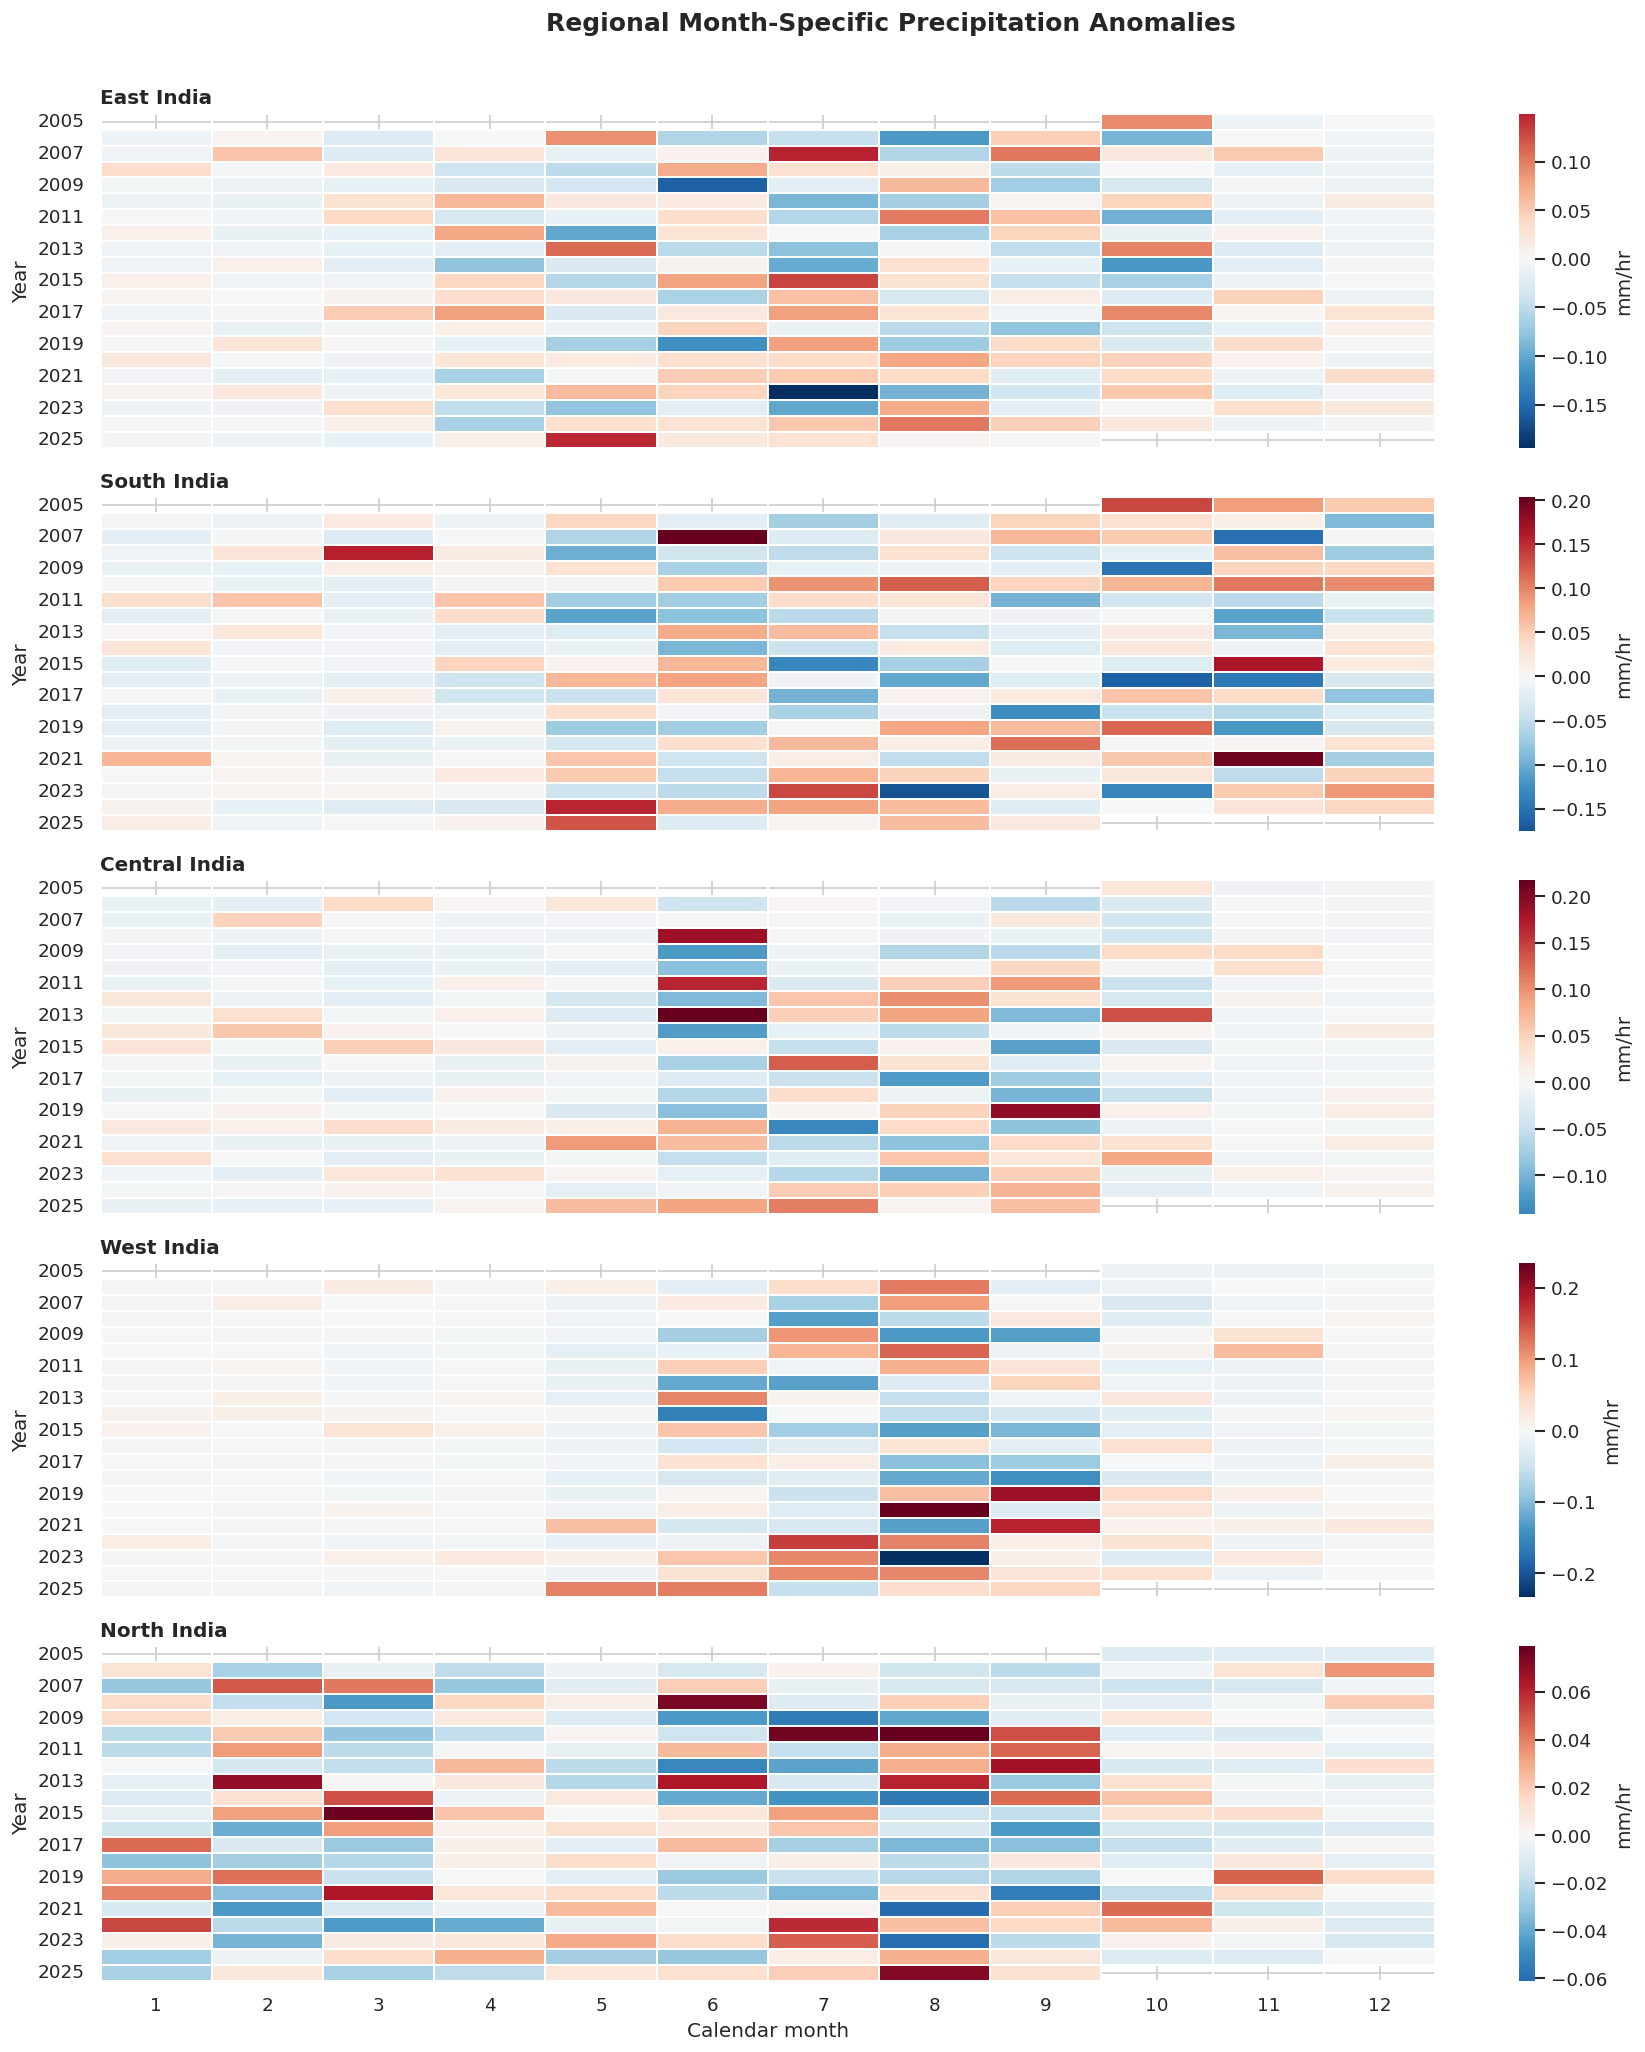

In [8]:
anomalies = df.copy()
anomalies["year"] = anomalies["date"].dt.year
anomalies["month"] = anomalies["date"].dt.month
for region in region_cols:
    month_mean = anomalies.groupby("month")[region].transform("mean")
    anomalies[region + "_anomaly"] = anomalies[region] - month_mean

fig, axes = plt.subplots(len(region_cols), 1, figsize=(15, 17), sharex=True)
if len(region_cols) == 1: axes = [axes]
for ax, region in zip(axes, region_cols):
    heat = anomalies.pivot(index="year", columns="month", values=region + "_anomaly")
    sns.heatmap(heat, ax=ax, cmap="RdBu_r", center=0, cbar_kws={"label": PRECIPITATION_UNIT}, linewidths=0.15)
    ax.set_title(region.replace("mean_", "").replace("_", " ").title(), loc="left", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Year")
axes[-1].set_xlabel("Calendar month")
fig.suptitle("Regional Month-Specific Precipitation Anomalies", y=1.005, fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_monthly_anomaly_heatmaps.png", bbox_inches="tight")
plt.show()
anomalies.to_csv(OUTPUT_DIR / "monthly_regional_anomalies.csv", index=False)

## 8. Annual mean-rate comparison and annual anomalies

Only complete calendar years with 12 valid monthly observations are retained. Because the input is a monthly value/rate series, the arithmetic mean of 12 monthly rates is an **annual mean rate**. It is **not annual accumulated rainfall**. Annual accumulation requires confirming the source variable's temporal semantics and converting each monthly mean rate using the actual hours in that month.

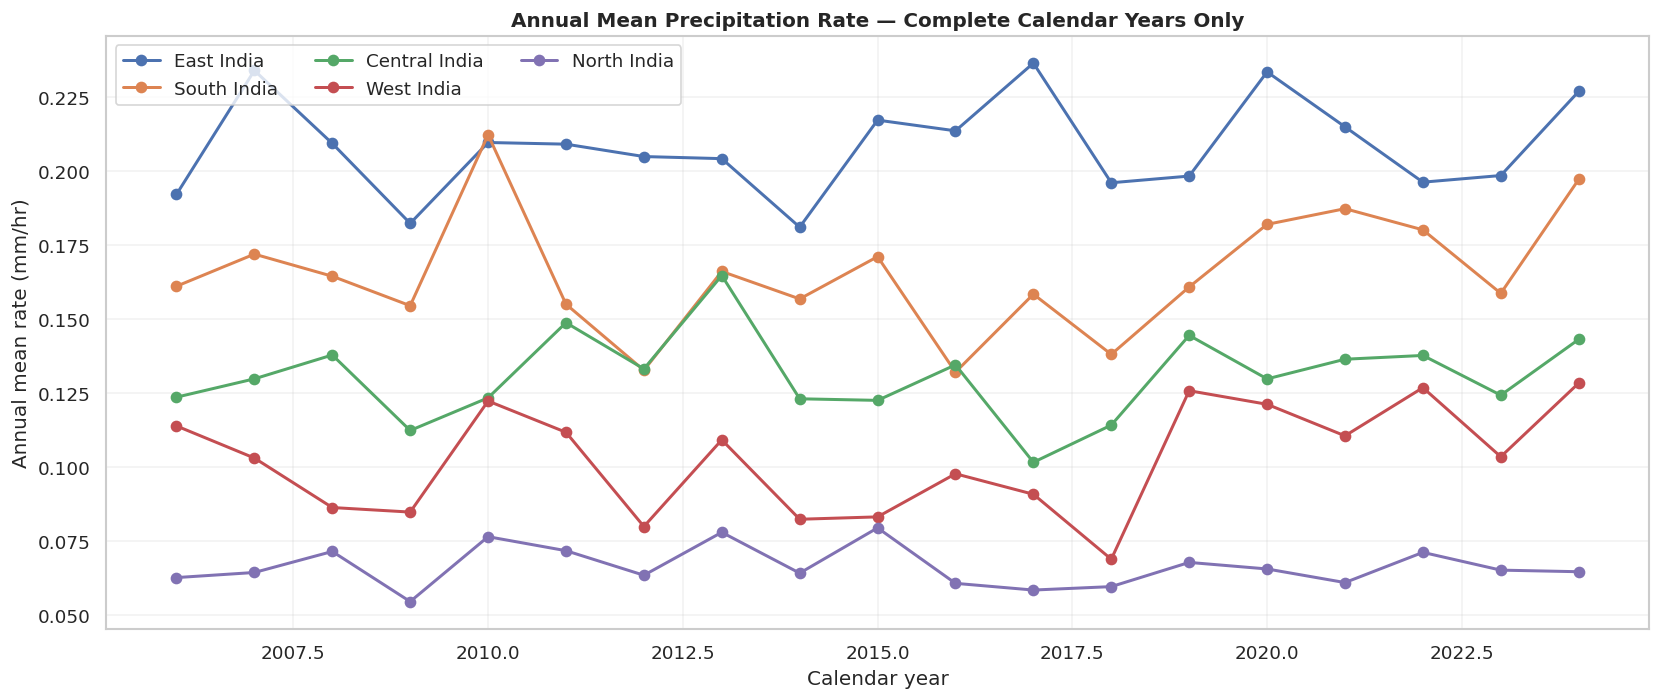

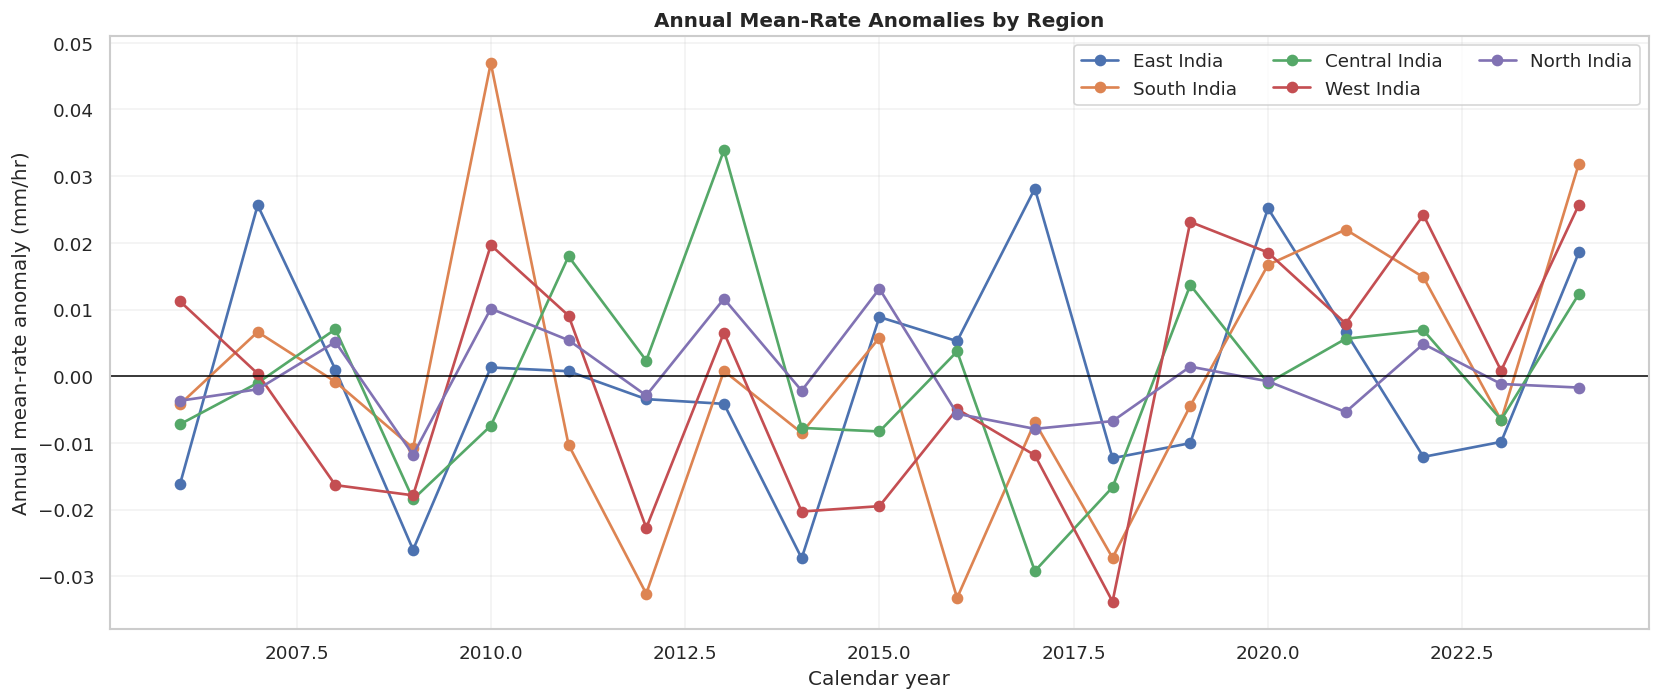

Complete calendar years: [np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]


In [9]:
annual_frames = []
for region in region_cols:
    tmp = df[["date", region]].copy()
    tmp["year"] = tmp["date"].dt.year
    agg = tmp.groupby("year")[region].agg(mean="mean", n_months="count")
    agg = agg[agg["n_months"] == 12].copy()
    agg["region"] = region
    annual_frames.append(agg.reset_index())
annual = pd.concat(annual_frames, ignore_index=True)

fig, ax = plt.subplots(figsize=(14, 6))
for region in region_cols:
    z = annual[annual["region"] == region]
    ax.plot(z["year"], z["mean"], marker="o", lw=1.8, label=region.replace("mean_", "").replace("_", " ").title())
ax.set_xlabel("Calendar year")
ax.set_ylabel(f"Annual mean rate ({PRECIPITATION_UNIT})")
ax.set_title("Annual Mean Precipitation Rate — Complete Calendar Years Only", fontweight="bold")
ax.legend(ncol=3)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_annual_mean_rate.png", bbox_inches="tight")
plt.show()

annual["annual_anomaly"] = annual.groupby("region")["mean"].transform(lambda x: x - x.mean())
fig, ax = plt.subplots(figsize=(14, 6))
for region in region_cols:
    z = annual[annual["region"] == region]
    ax.plot(z["year"], z["annual_anomaly"], marker="o", lw=1.6, label=region.replace("mean_", "").replace("_", " ").title())
ax.axhline(0, color="black", lw=0.9)
ax.set_xlabel("Calendar year")
ax.set_ylabel(f"Annual mean-rate anomaly ({PRECIPITATION_UNIT})")
ax.set_title("Annual Mean-Rate Anomalies by Region", fontweight="bold")
ax.legend(ncol=3)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_annual_anomalies.png", bbox_inches="tight")
plt.show()
annual.to_csv(OUTPUT_DIR / "annual_regional_mean_rates_and_anomalies.csv", index=False)
print("Complete calendar years:", sorted(annual["year"].unique()))

## 9. Statistical methods

### 9.1 HAC-robust linear regression

The fitted linear slope is expressed per year. Newey–West heteroskedasticity/autocorrelation-consistent (HAC) standard errors use 12 monthly lags. This makes the regression inference more robust to short-range serial dependence than ordinary OLS standard errors, although it does not fix an incorrect linear model or missing spatial provenance.

### 9.2 Seasonal Mann–Kendall and seasonal Sen slope

The seasonal test compares observations **within the same calendar month** across different years, so January is compared with January, February with February, etc. The seasonal Sen slope is the median of pairwise slopes within calendar months, with time measured in years. It therefore has units of source-unit/year.

### 9.3 Autocorrelation caveat

We inspect month-specific anomalies using lag-1 autocorrelation and a Ljung–Box test through lag 12. The standard seasonal Mann–Kendall p-value below is not automatically corrected for serial autocorrelation. Where the diagnostic indicates significant autocorrelation, interpret the MK p-value cautiously and consider a dedicated modified seasonal MK procedure as a sensitivity analysis.

In [10]:
# 9.4 Reproducible seasonal Kendall and seasonal Sen estimators

def seasonal_kendall_test(values, dates, alpha=0.05):
    """Seasonal Kendall test: within-calendar-month pair comparisons with tie-corrected variance."""
    temp = pd.DataFrame({"date": pd.to_datetime(dates), "value": np.asarray(values, dtype=float)})
    temp["month"] = temp["date"].dt.month
    S_total, var_total, denom = 0.0, 0.0, 0.0
    n_used = 0
    for _, g in temp.groupby("month"):
        y = g["value"].to_numpy()
        n = len(y)
        n_used += n
        if n < 2:
            continue
        diffs = y[np.newaxis, :] - y[:, np.newaxis]
        iu = np.triu_indices(n, k=1)
        d = diffs[iu]
        S_total += np.sign(d).sum()
        denom += n * (n - 1) / 2
        _, counts = np.unique(y, return_counts=True)
        tie_term = np.sum(counts * (counts - 1) * (2 * counts + 5))
        var_total += (n * (n - 1) * (2 * n + 5) - tie_term) / 18
    if var_total <= 0 or denom <= 0:
        return {"S": S_total, "Tau": np.nan, "Z": np.nan, "p": np.nan, "n": n_used}
    if S_total > 0:
        z = (S_total - 1) / np.sqrt(var_total)
    elif S_total < 0:
        z = (S_total + 1) / np.sqrt(var_total)
    else:
        z = 0.0
    p = 2 * norm.sf(abs(z))
    return {"S": S_total, "Tau": S_total / denom, "Z": z, "p": p, "n": n_used}


def seasonal_sen_slope(values, dates):
    """Median within-calendar-month pairwise slopes; units = value units per year."""
    temp = pd.DataFrame({"date": pd.to_datetime(dates), "value": np.asarray(values, dtype=float)})
    temp["month"] = temp["date"].dt.month
    slopes = []
    for _, g in temp.groupby("month"):
        g = g.sort_values("date")
        x = g["date"].map(lambda d: d.toordinal() / 365.2425).to_numpy(dtype=float)
        y = g["value"].to_numpy(dtype=float)
        if len(y) < 2:
            continue
        i, j = np.triu_indices(len(y), k=1)
        valid = x[j] != x[i]
        slopes.extend(((y[j[valid]] - y[i[valid]]) / (x[j[valid]] - x[i[valid]])).tolist())
    return float(np.median(slopes)) if slopes else np.nan


def anomaly_autocorrelation_diagnostics(series):
    """ACF/Ljung-Box diagnostics on month-of-year demeaned anomalies."""
    s = pd.Series(series).astype(float)
    month = s.index.month
    anom = s.to_numpy() - pd.Series(s.to_numpy()).groupby(month).transform("mean").to_numpy()
    lag1 = float(acf(anom, nlags=1, fft=True)[1]) if len(anom) > 3 else np.nan
    lb = acorr_ljungbox(anom, lags=[12], return_df=True)
    return lag1, float(lb["lb_pvalue"].iloc[0])

print("Statistical helper functions defined.")

Statistical helper functions defined.


In [11]:
# 9.5 Estimate all regional trends
trend_rows = []
for region in region_cols:
    temp = df[["date", region]].dropna().copy()
    dates = temp["date"]
    y = temp[region].to_numpy(dtype=float)
    x_years = (dates - dates.min()).dt.days.to_numpy(dtype=float) / 365.2425

    X = sm.add_constant(x_years)
    hac_fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_MAXLAGS})
    linear_slope = float(hac_fit.params[1])
    linear_p = float(hac_fit.pvalues[1])
    linear_ci_low, linear_ci_high = map(float, hac_fit.conf_int(alpha=ALPHA)[1])
    r_squared = float(sm.OLS(y, X).fit().rsquared)

    sk = seasonal_kendall_test(y, dates, alpha=ALPHA)
    ss_slope = seasonal_sen_slope(y, dates)
    ordinary_sen = theilslopes(y, x_years, alpha=1-ALPHA)

    lag1, lb12_p = anomaly_autocorrelation_diagnostics(temp.set_index("date")[region])
    trend_rows.append({
        "Region": region.replace("mean_", "").replace("_", " ").title(),
        "Mean value": float(np.mean(y)),
        "Linear slope per year": linear_slope,
        "HAC linear p-value": linear_p,
        "HAC linear 95% CI lower": linear_ci_low,
        "HAC linear 95% CI upper": linear_ci_high,
        "R-squared (descriptive)": r_squared,
        "Seasonal Sen slope per year": ss_slope,
        "Seasonal MK Tau": sk["Tau"],
        "Seasonal MK Z": sk["Z"],
        "Seasonal MK p-value": sk["p"],
        "Ordinary Theil-Sen slope per year": float(ordinary_sen.slope),
        "Ordinary Sen 95% CI lower": float(ordinary_sen.low_slope),
        "Ordinary Sen 95% CI upper": float(ordinary_sen.high_slope),
        "Anomaly lag-1 ACF": lag1,
        "Ljung-Box p-value (lag 12)": lb12_p,
        "Autocorrelation flagged": bool(lb12_p < ALPHA),
    })

trend_results = pd.DataFrame(trend_rows)
trend_results["Seasonal MK p-value (BH adjusted)"] = multipletests(
    trend_results["Seasonal MK p-value"].fillna(1.0), alpha=ALPHA, method="fdr_bh"
)[1]
trend_results["Seasonal MK significant (raw p<0.05)"] = trend_results["Seasonal MK p-value"] < ALPHA
trend_results["Seasonal MK significant (BH q<0.05)"] = trend_results["Seasonal MK p-value (BH adjusted)"] < ALPHA
trend_results["Trend direction (seasonal Sen)"] = np.where(
    trend_results["Seasonal Sen slope per year"] > 0, "Increasing",
    np.where(trend_results["Seasonal Sen slope per year"] < 0, "Decreasing", "No estimated change")
)
trend_results = trend_results.sort_values("Seasonal Sen slope per year", ascending=False).reset_index(drop=True)
display(trend_results.round(6))
trend_results.to_csv(OUTPUT_DIR / "regional_statistical_trend_results.csv", index=False)

,Region,Mean value,Linear slope per year,HAC linear p-value,HAC linear 95% CI lower,HAC linear 95% CI upper,R-squared (descriptive),Seasonal Sen slope per year,Seasonal MK Tau,Seasonal MK Z,Seasonal MK p-value,Ordinary Theil-Sen slope per year,Ordinary Sen 95% CI lower,Ordinary Sen 95% CI upper,Anomaly lag-1 ACF,Ljung-Box p-value (lag 12),Autocorrelation flagged,Seasonal MK p-value (BH adjusted),Seasonal MK significant (raw p<0.05),Seasonal MK significant (BH q<0.05),Trend direction (seasonal Sen)
0,South India,0.167285,0.000859,0.338098,-0.000898,0.002615,0.001638,0.000537,0.054386,1.152001,0.249321,0.000662,-0.001474,0.003007,0.115459,0.126812,False,0.311651,False,False,Increasing
1,Central India,0.132040,0.001601,0.170139,-0.000686,0.003888,0.003005,0.000348,0.079825,1.695220,0.090034,0.000479,-0.000268,0.001467,0.088233,0.057615,False,0.235738,False,False,Increasing
2,East India,0.209341,0.001821,0.169020,-0.000774,0.004417,0.002924,0.000296,0.069298,1.470440,0.141443,0.000922,-0.000910,0.003244,0.011085,0.709772,False,0.235738,False,False,Increasing
3,West India,0.103516,0.002094,0.043685,0.000059,0.004128,0.006881,0.000097,0.071930,1.526635,0.126852,0.000128,-0.000115,0.000541,0.129809,0.134549,False,0.235738,False,False,Increasing
4,North India,0.066373,0.000330,0.446880,-0.000520,0.001180,0.001291,0.000085,0.018421,0.384000,0.700978,0.000260,-0.000599,0.001225,0.141003,0.275746,False,0.700978,False,False,Increasing


## 10. Regional trend ranking

The ranking is based on the **absolute seasonal Sen slope**. The sign indicates direction. This ranks estimated magnitude only; it does not rank statistical certainty. Always read the slope together with the Seasonal MK p-value, BH-adjusted q-value and autocorrelation diagnostic.

In [12]:
ranking = trend_results.copy()
ranking["Absolute seasonal Sen slope"] = ranking["Seasonal Sen slope per year"].abs()
ranking = ranking.sort_values("Absolute seasonal Sen slope", ascending=False)
display(ranking[["Region", "Seasonal Sen slope per year", "Absolute seasonal Sen slope",
                 "Seasonal MK p-value", "Seasonal MK p-value (BH adjusted)",
                 "Autocorrelation flagged"]].round(6))

,Region,Seasonal Sen slope per year,Absolute seasonal Sen slope,Seasonal MK p-value,Seasonal MK p-value (BH adjusted),Autocorrelation flagged
0,South India,0.000537,0.000537,0.249321,0.311651,False
1,Central India,0.000348,0.000348,0.090034,0.235738,False
2,East India,0.000296,0.000296,0.141443,0.235738,False
3,West India,0.000097,0.000097,0.126852,0.235738,False
4,North India,0.000085,0.000085,0.700978,0.700978,False


## 11. Trend visualizations

The solid line is the HAC-OLS fitted linear trend. Its 95% confidence band uses the HAC covariance matrix for the fitted mean. The seasonal Sen slope is reported in the title for comparison; it is not the line drawn in this plot.

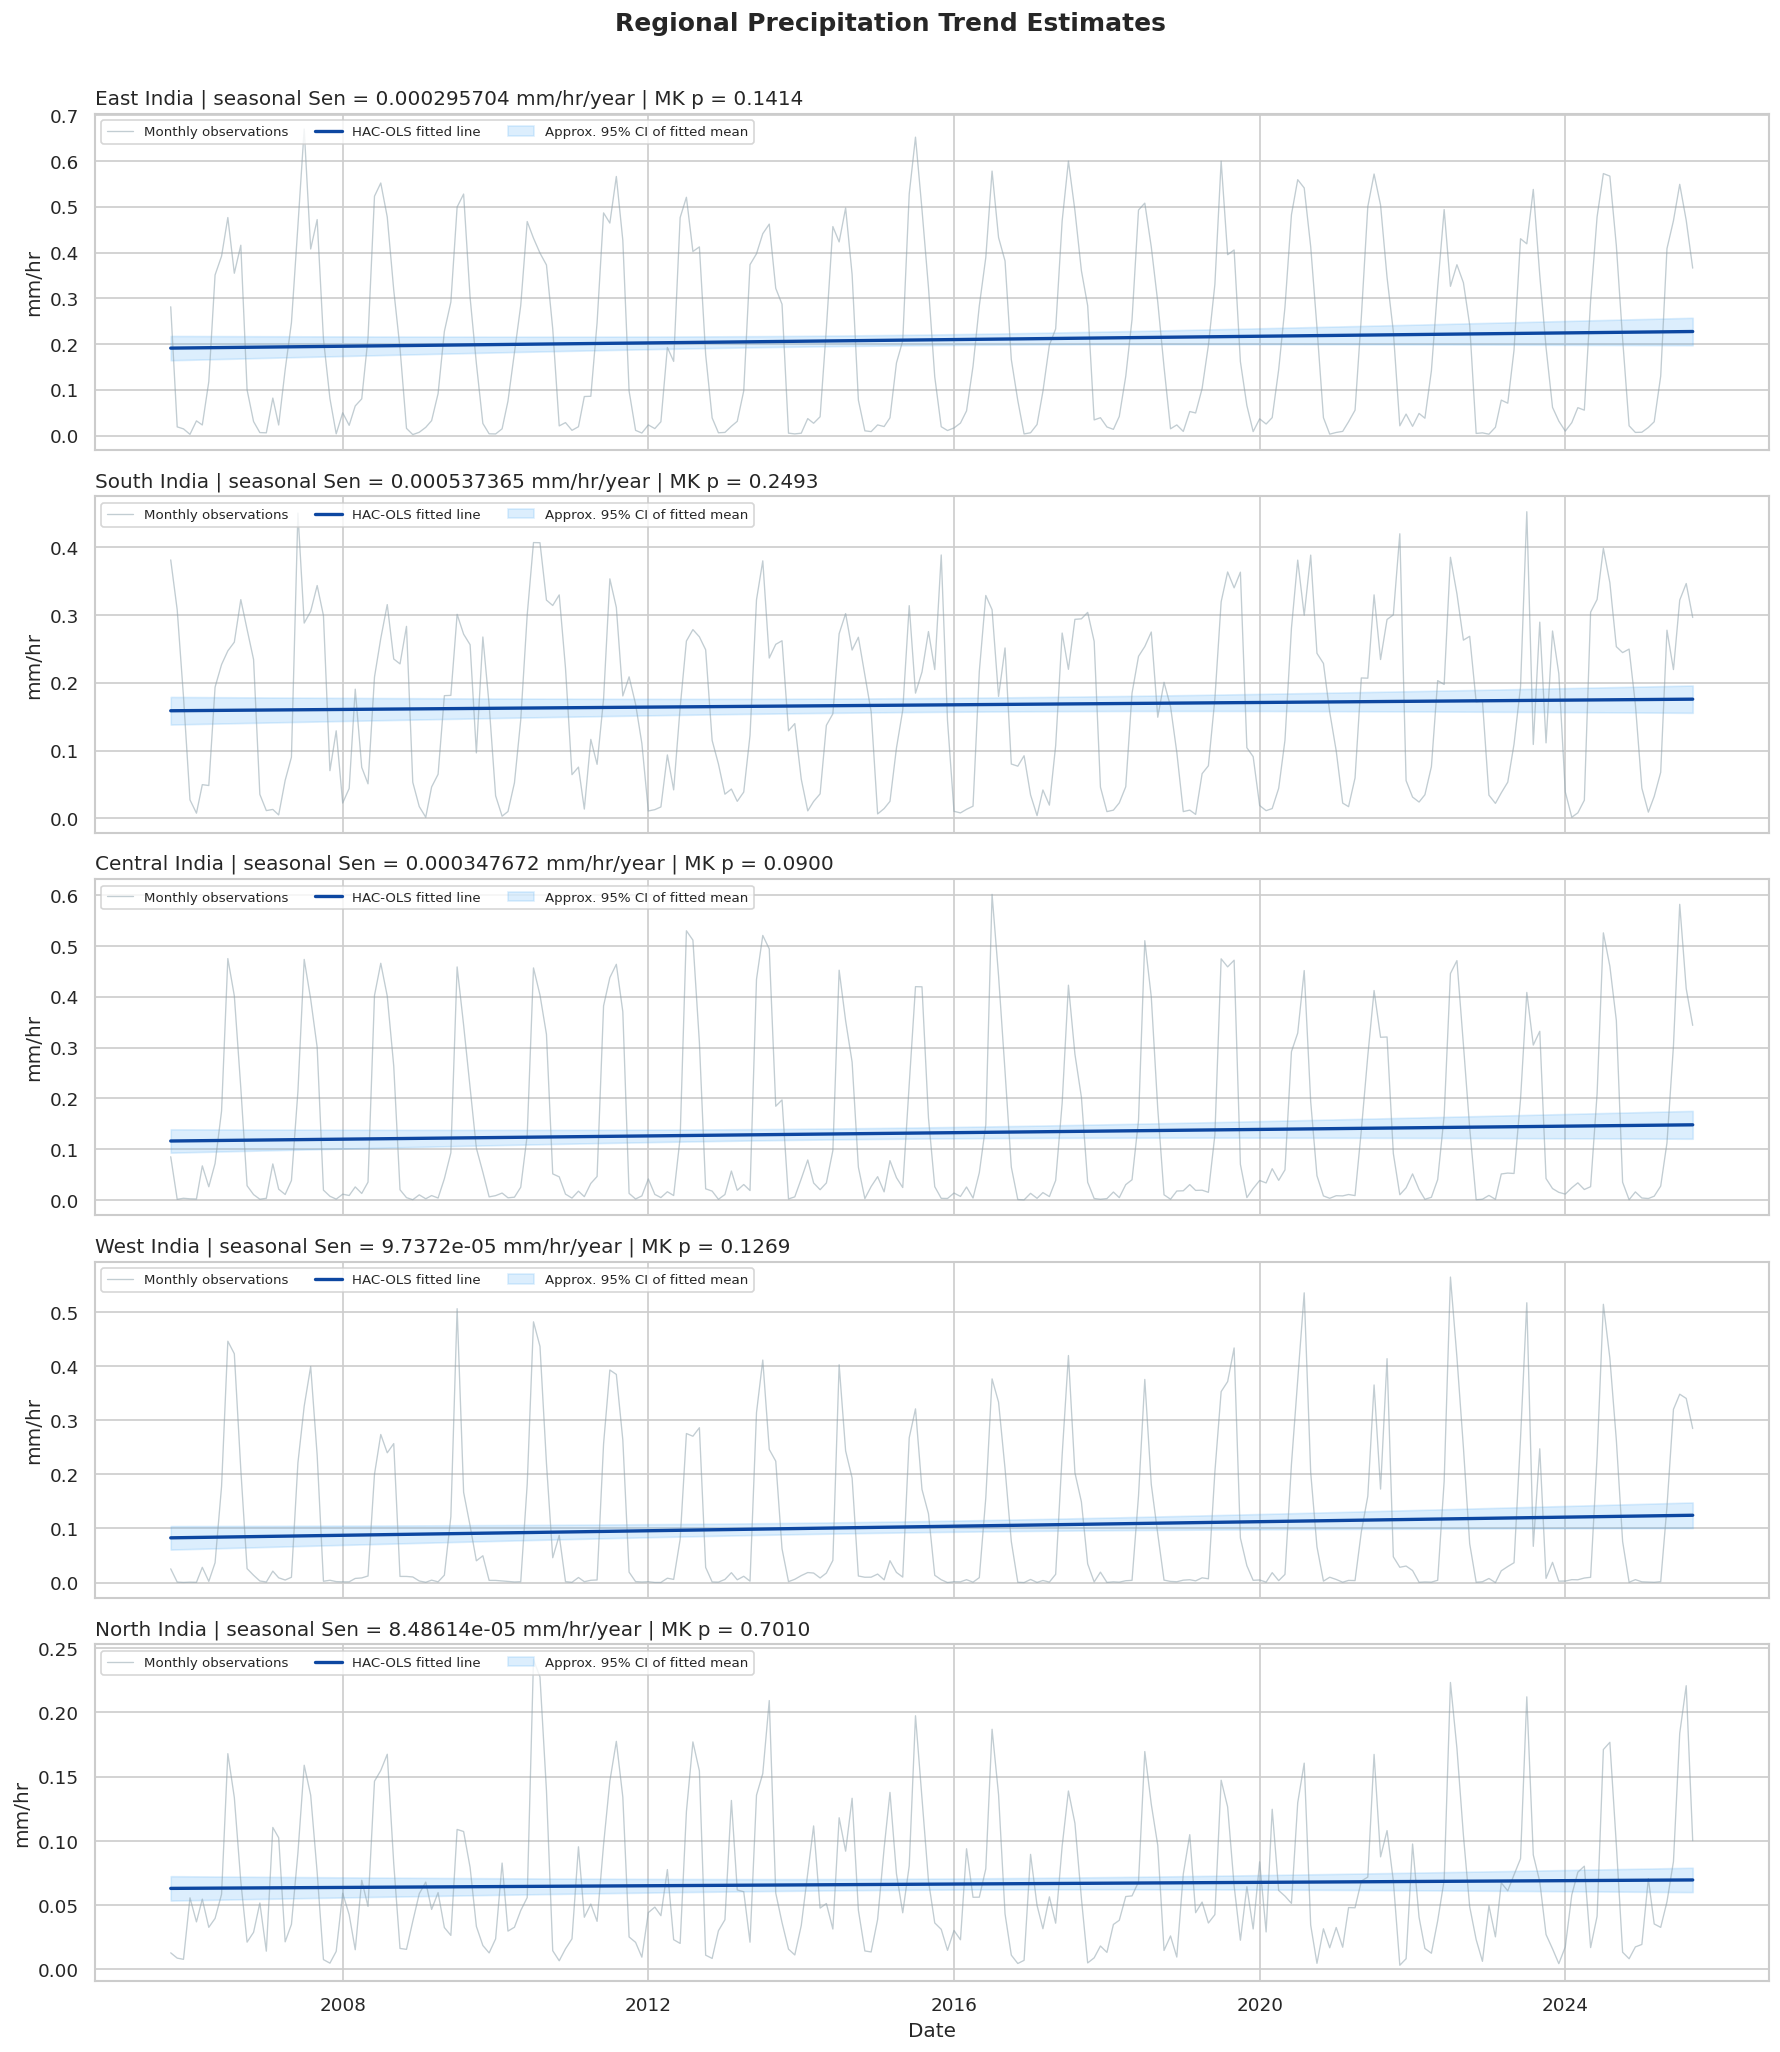

In [13]:
fig, axes = plt.subplots(len(region_cols), 1, figsize=(15, 17), sharex=True)
if len(region_cols) == 1: axes = [axes]
for ax, region in zip(axes, region_cols):
    temp = df[["date", region]].dropna()
    dates = temp["date"]
    y = temp[region].to_numpy(float)
    x = (dates - dates.min()).dt.days.to_numpy(float) / 365.2425
    X = sm.add_constant(x)
    fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_MAXLAGS})
    pred = fit.predict(X)
    cov = np.asarray(fit.cov_params())
    pred_var = np.einsum("ij,jk,ik->i", X, cov, X)
    margin = 1.96 * np.sqrt(np.maximum(pred_var, 0))
    row = trend_results.loc[trend_results["Region"] == region.replace("mean_", "").replace("_", " ").title()].iloc[0]

    ax.plot(dates, y, color="#90a4ae", lw=0.8, alpha=0.55, label="Monthly observations")
    ax.plot(dates, pred, color="#0d47a1", lw=2.0, label="HAC-OLS fitted line")
    ax.fill_between(dates, pred-margin, pred+margin, color="#42a5f5", alpha=0.18, label="Approx. 95% CI of fitted mean")
    ax.set_title(f"{row['Region']} | seasonal Sen = {row['Seasonal Sen slope per year']:.6g} {PRECIPITATION_UNIT}/year | MK p = {row['Seasonal MK p-value']:.4f}", loc="left")
    ax.set_ylabel(PRECIPITATION_UNIT)
    ax.legend(loc="upper left", ncol=3, fontsize=8)
axes[-1].set_xlabel("Date")
fig.suptitle("Regional Precipitation Trend Estimates", y=1.005, fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_regional_trend_fits.png", bbox_inches="tight")
plt.show()

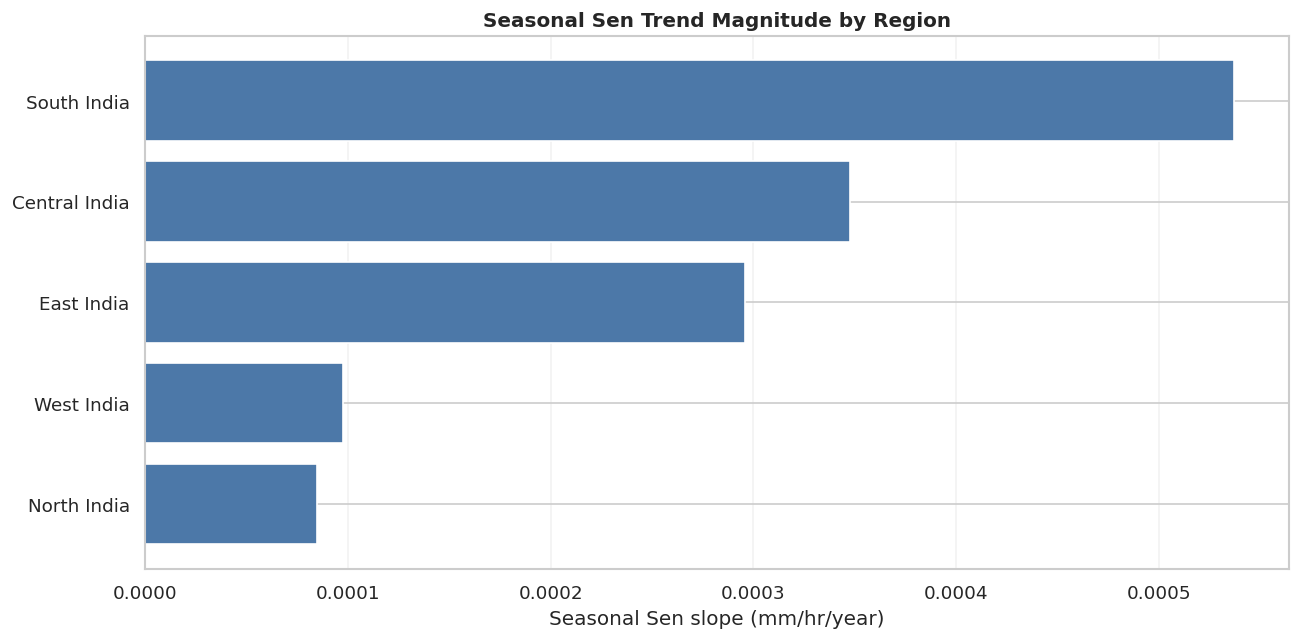

In [14]:
# 11.1 Seasonal Sen slope comparison
plot_df = trend_results.sort_values("Seasonal Sen slope per year")
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(plot_df["Region"], plot_df["Seasonal Sen slope per year"], color="#4c78a8")
ax.axvline(0, color="black", lw=0.9)
ax.set_xlabel(f"Seasonal Sen slope ({PRECIPITATION_UNIT}/year)")
ax.set_title("Seasonal Sen Trend Magnitude by Region", fontweight="bold")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07_seasonal_sen_comparison.png", bbox_inches="tight")
plt.show()

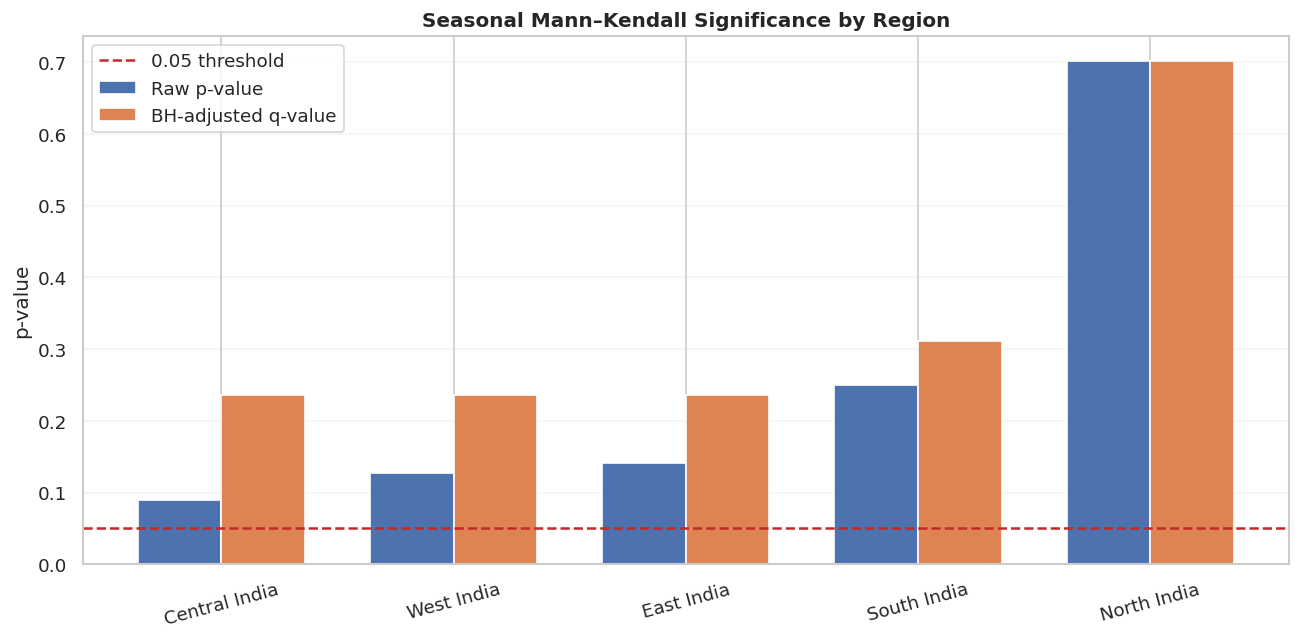

In [15]:
# 11.2 Seasonal Mann–Kendall significance with raw and BH-adjusted p-values
sig = trend_results.sort_values("Seasonal MK p-value")
fig, ax = plt.subplots(figsize=(11, 5.5))
xpos = np.arange(len(sig))
ax.bar(xpos-0.18, sig["Seasonal MK p-value"], width=0.36, label="Raw p-value")
ax.bar(xpos+0.18, sig["Seasonal MK p-value (BH adjusted)"], width=0.36, label="BH-adjusted q-value")
ax.axhline(ALPHA, color="#c62828", linestyle="--", lw=1.5, label="0.05 threshold")
ax.set_xticks(xpos, sig["Region"], rotation=15)
ax.set_ylabel("p-value")
ax.set_title("Seasonal Mann–Kendall Significance by Region", fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "08_seasonal_mk_significance.png", bbox_inches="tight")
plt.show()

## 12. Statistical interpretation and decision rules

- **Direction and magnitude:** use the sign and value of the seasonal Sen slope.
- **Seasonal MK evidence:** raw p-value below 0.05 indicates nominal significance. Because five regional tests are performed, also report the Benjamini–Hochberg adjusted q-value.
- **Autocorrelation:** if Ljung–Box p-value is below 0.05, serial dependence is flagged. The standard Seasonal MK p-value remains unadjusted for this dependence and must be described as provisional pending a modified test.
- **No significance is not proof of no change.** It means the data do not provide sufficient evidence to reject the no-monotonic-trend null at the chosen threshold.
- The OLS/HAC slope is a linear-model estimate; the seasonal Sen slope is a robust, seasonally stratified estimate. Their numerical values need not be identical.

In [16]:
def interpret_row(row):
    slope = row["Seasonal Sen slope per year"]
    direction = "increasing" if slope > 0 else "decreasing" if slope < 0 else "approximately flat"
    p = row["Seasonal MK p-value"]
    q = row["Seasonal MK p-value (BH adjusted)"]
    nominal = "nominally significant" if p < ALPHA else "not nominally significant"
    fdr = "remains significant after BH correction" if q < ALPHA else "does not remain significant after BH correction"
    acf_note = "Autocorrelation is flagged; interpret the standard Seasonal MK p-value cautiously." if row["Autocorrelation flagged"] else "The lag-12 Ljung–Box diagnostic did not flag autocorrelation at 0.05."
    return (f"{row['Region']}: estimated {direction} seasonal trend of {slope:.6g} {PRECIPITATION_UNIT}/year; "
            f"Seasonal MK p={p:.4g} ({nominal}) and BH-adjusted q={q:.4g} ({fdr}). {acf_note}")

for _, row in trend_results.iterrows():
    print("•", interpret_row(row))

• South India: estimated increasing seasonal trend of 0.000537365 mm/hr/year; Seasonal MK p=0.2493 (not nominally significant) and BH-adjusted q=0.3117 (does not remain significant after BH correction). The lag-12 Ljung–Box diagnostic did not flag autocorrelation at 0.05.
• Central India: estimated increasing seasonal trend of 0.000347672 mm/hr/year; Seasonal MK p=0.09003 (not nominally significant) and BH-adjusted q=0.2357 (does not remain significant after BH correction). The lag-12 Ljung–Box diagnostic did not flag autocorrelation at 0.05.
• East India: estimated increasing seasonal trend of 0.000295704 mm/hr/year; Seasonal MK p=0.1414 (not nominally significant) and BH-adjusted q=0.2357 (does not remain significant after BH correction). The lag-12 Ljung–Box diagnostic did not flag autocorrelation at 0.05.
• West India: estimated increasing seasonal trend of 9.7372e-05 mm/hr/year; Seasonal MK p=0.1269 (not nominally significant) and BH-adjusted q=0.2357 (does not remain significant 

## 13. Final regional results table

This is the main machine-readable result for the dashboard/report. It deliberately keeps the statistical estimators and tests in separate columns so that the user does not confuse a slope estimate with a significance test.

In [17]:
final_columns = [
    "Region", "Mean value", "Linear slope per year", "HAC linear p-value",
    "HAC linear 95% CI lower", "HAC linear 95% CI upper", "R-squared (descriptive)",
    "Seasonal Sen slope per year", "Seasonal MK Tau", "Seasonal MK Z",
    "Seasonal MK p-value", "Seasonal MK p-value (BH adjusted)",
    "Seasonal MK significant (raw p<0.05)", "Seasonal MK significant (BH q<0.05)",
    "Ordinary Theil-Sen slope per year", "Ordinary Sen 95% CI lower", "Ordinary Sen 95% CI upper",
    "Anomaly lag-1 ACF", "Ljung-Box p-value (lag 12)", "Autocorrelation flagged",
    "Trend direction (seasonal Sen)"
]
final_table = trend_results[final_columns].copy()
display(final_table.round(6))
final_table.to_csv(OUTPUT_DIR / "final_regional_trend_summary.csv", index=False)

,Region,Mean value,Linear slope per year,HAC linear p-value,HAC linear 95% CI lower,HAC linear 95% CI upper,R-squared (descriptive),Seasonal Sen slope per year,Seasonal MK Tau,Seasonal MK Z,Seasonal MK p-value,Seasonal MK p-value (BH adjusted),Seasonal MK significant (raw p<0.05),Seasonal MK significant (BH q<0.05),Ordinary Theil-Sen slope per year,Ordinary Sen 95% CI lower,Ordinary Sen 95% CI upper,Anomaly lag-1 ACF,Ljung-Box p-value (lag 12),Autocorrelation flagged,Trend direction (seasonal Sen)
0,South India,0.167285,0.000859,0.338098,-0.000898,0.002615,0.001638,0.000537,0.054386,1.152001,0.249321,0.311651,False,False,0.000662,-0.001474,0.003007,0.115459,0.126812,False,Increasing
1,Central India,0.132040,0.001601,0.170139,-0.000686,0.003888,0.003005,0.000348,0.079825,1.695220,0.090034,0.235738,False,False,0.000479,-0.000268,0.001467,0.088233,0.057615,False,Increasing
2,East India,0.209341,0.001821,0.169020,-0.000774,0.004417,0.002924,0.000296,0.069298,1.470440,0.141443,0.235738,False,False,0.000922,-0.000910,0.003244,0.011085,0.709772,False,Increasing
3,West India,0.103516,0.002094,0.043685,0.000059,0.004128,0.006881,0.000097,0.071930,1.526635,0.126852,0.235738,False,False,0.000128,-0.000115,0.000541,0.129809,0.134549,False,Increasing
4,North India,0.066373,0.000330,0.446880,-0.000520,0.001180,0.001291,0.000085,0.018421,0.384000,0.700978,0.700978,False,False,0.000260,-0.000599,0.001225,0.141003,0.275746,False,Increasing


## 14. Research conclusion template

Use the generated values in `final_regional_trend_summary.csv` to write the final narrative. Do not claim a region is experiencing a statistically established increase/decrease unless the relevant test supports that statement and the autocorrelation/provenance limitations have been addressed.

In [18]:
print("STUDY PERIOD:", df["date"].min().strftime("%b %Y"), "to", df["date"].max().strftime("%b %Y"))
print("MONTHLY OBSERVATIONS PER REGION:", int(df[region_cols].count().min()), "to", int(df[region_cols].count().max()))
print("SOURCE UNIT LABEL:", PRECIPITATION_UNIT)
print("\nTOP REGION BY ABSOLUTE SEASONAL SEN MAGNITUDE:")
top = trend_results.iloc[trend_results["Seasonal Sen slope per year"].abs().argmax()]
print(f"{top['Region']} ({top['Seasonal Sen slope per year']:.6g} {PRECIPITATION_UNIT}/year)")
print("\nREGIONS WITH NOMINAL SEASONAL MK p < 0.05:",
      trend_results.loc[trend_results["Seasonal MK p-value"] < ALPHA, "Region"].tolist() or "None")
print("REGIONS WITH BH-ADJUSTED q < 0.05:",
      trend_results.loc[trend_results["Seasonal MK p-value (BH adjusted)"] < ALPHA, "Region"].tolist() or "None")
print("REGIONS WITH AUTOCORRELATION FLAG:",
      trend_results.loc[trend_results["Autocorrelation flagged"], "Region"].tolist() or "None")
print("\nCAUTION: The regional boundaries, area-weighting, product metadata and extraction workflow must be documented before these are treated as reproducible regional climate estimates.")

STUDY PERIOD: Oct 2005 to Sep 2025
MONTHLY OBSERVATIONS PER REGION: 240 to 240
SOURCE UNIT LABEL: mm/hr

TOP REGION BY ABSOLUTE SEASONAL SEN MAGNITUDE:
South India (0.000537365 mm/hr/year)

REGIONS WITH NOMINAL SEASONAL MK p < 0.05: None
REGIONS WITH BH-ADJUSTED q < 0.05: None
REGIONS WITH AUTOCORRELATION FLAG: None

CAUTION: The regional boundaries, area-weighting, product metadata and extraction workflow must be documented before these are treated as reproducible regional climate estimates.


## 15. Export inventory and reproducibility checklist

The `regional_analysis_outputs/` folder contains the derived tables and figures. Before final submission, complete and independently verify:

- [ ] Exact NASA product/version, variable name and units copied from the source metadata.
- [ ] Temporal statistic confirmed (monthly mean rate versus monthly accumulation).
- [ ] Five region boundaries documented (state list or polygon file/version).
- [ ] Regional mean method documented (area-weighted or unweighted; treatment of land/ocean cells).
- [ ] Extraction workflow documented and reproducible from the original gridded source.
- [ ] Spatial resolution, date range, download date and source request/file ID recorded.
- [ ] The notebook has been run top-to-bottom with the CSV in the same directory.
- [ ] Any autocorrelation-flagged regions receive a modified seasonal MK sensitivity test before strong inferential claims are made.

**Scope statement:** this notebook completes the regional time-series analysis for the five supplied regional columns. It does not by itself create a selectable multi-variable public web application, nor does it establish the correctness of the region masks without the corresponding boundaries and extraction metadata.